# 🐞 BugAssist Data Fusion — Exploratory Data Analysis

**Dataset:** `BugAssistDataFusion_1.xlsx` (1,000 bug records enriched with GitHub, StackOverflow, CVE and news signals)

**What this notebook does**
1. Loads the Excel file and **removes the Gemini-generated columns** (`gemini_*`)
2. Audits data quality (missing values, duplicates, validity, logical consistency)
3. Univariate, categorical, bivariate and group-wise analysis with statistical tests
4. Temporal analysis, hierarchy / leakage checks and a final summary of findings

> **Note on the Gemini columns:** you described them as completely empty. In the file supplied, all three `gemini_*` columns are **fully populated** (0 missing). They are dropped anyway, as requested. Section 1 shows the check, and `DROP_GEMINI = False` keeps them.

## 0 · Setup

In [2]:
import os, re, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 200)

FILE_PATH = "BugAssistDataFusion_1.xlsx"   # change if your file lives elsewhere
DROP_GEMINI = True                          # set False to keep the gemini_* columns

# Google Colab convenience: prompt for upload if the file is not present
if not os.path.exists(FILE_PATH):
    try:
        from google.colab import files
        FILE_PATH = next(iter(files.upload()))
    except ImportError:
        raise FileNotFoundError(f"Put the Excel file next to this notebook or fix FILE_PATH: {FILE_PATH}")

## 1 · Load data and remove the Gemini columns

In [4]:
df_raw = pd.read_excel(FILE_PATH)
print(f"Raw shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
df_raw.head()

Raw shape: 1,000 rows x 17 columns


,bug_id,title,gemini_root_cause_analysis,gemini_fix_confidence_score,gemini_priority_recommendation,github_similar_issues_count,github_top_issue_url,github_top_issue_comments,stackoverflow_question_count,stackoverflow_top_answer_score,stackoverflow_top_question_url,cve_related_count,cve_top_id,cve_top_severity_score,news_related_count,news_latest_title,news_latest_date
0,BUG_000001,API Bug detected in system,"The API bug in the Spring Boot application likely stems from incorrect request/response handling, improper exception management, or misconfigured endpoints/interceptors.",7,Medium,8247,https://github.com/vaadin/flow/issues/16664,276,2,19,https://stackoverflow.com/questions/40051078/spring-security-api-gateway-pattern-bug,42,CVE-2019-61357,6.5,186,How a freshman elevated to starting placekicker for Purdue football,2026-08-29T08:01:45Z
1,BUG_000002,Memory Leak detected in system,"The memory leak is likely caused by unmanaged object retention in the GCP-based application, where allocated memory is not properly released after use, leading to gradual memory exhaustion.",9,Critical,1094,https://github.com/mizunotaro/crm-lab-sandbox/issues/9,12,5,0,NaN,9,CVE-2026-97115,6.8,335,prema-agentshield added to PyPI,2026-08-29T20:55:53Z
2,BUG_000003,Cloud Configuration Bug detected in system,"The bug likely stems from incorrect or misconfigured cloud service settings in the Django application, potentially affecting resource allocation, security policies, or environment variables.",8,High,306,https://github.com/coollabsio/coolify/issues/3597,50,2,1,https://stackoverflow.com/questions/63712861/fail-to-deploy-project-to-google-cloud-app-engine-standard,23,CVE-2022-72675,7.7,2036,django-todo 2.7.0,2026-08-29T20:57:59Z
3,BUG_000004,Authentication Bug detected in system,"The authentication bug is likely due to improper session handling or flawed credential validation in the Flask application, allowing unauthorized access or failed authentication attempts.",8,High,851,https://github.com/codescalersinternships/home/issues/114,136,3,17,https://stackoverflow.com/questions/72944699/flask-login-user-always-not-authenticated,13,CVE-2026-17280,4.0,513,loomtrace added to PyPI,2026-08-29T20:54:26Z
4,BUG_000005,Logging Bug detected in system,"The logging bug in the Flask application is likely due to improper configuration or usage of the logging module, such as missing log levels, incorrect handlers, or unhandled exceptions not being logged.",8,Medium,851,https://github.com/codescalersinternships/home/issues/114,142,9,11,https://stackoverflow.com/questions/72944699/flask-login-user-always-not-authenticated,8,CVE-2024-82093,9.3,513,loomtrace added to PyPI,2026-08-29T20:54:26Z


### 1.1 Verify the Gemini columns before dropping them

In [6]:
gemini_cols = [c for c in df_raw.columns if c.lower().startswith("gemini")]
check = pd.DataFrame({
    "non_null":      df_raw[gemini_cols].notna().sum(),
    "missing":       df_raw[gemini_cols].isna().sum(),
    "blank_strings": [(df_raw[c].astype(str).str.strip() == "").sum() for c in gemini_cols],
    "unique_values": df_raw[gemini_cols].nunique(),
})
check["missing_%"] = (check["missing"] / len(df_raw) * 100).round(1)
print("Gemini-based columns found:", gemini_cols)
check

Gemini-based columns found: ['gemini_root_cause_analysis', 'gemini_fix_confidence_score', 'gemini_priority_recommendation']


,non_null,missing,blank_strings,unique_values,missing_%
gemini_root_cause_analysis,1000,0,0,952,0.0
gemini_fix_confidence_score,1000,0,0,9,0.0
gemini_priority_recommendation,1000,0,0,4,0.0


In [7]:
df = df_raw.drop(columns=gemini_cols) if DROP_GEMINI else df_raw.copy()
print(f"Working shape after dropping Gemini columns: {df.shape[0]:,} rows x {df.shape[1]} columns")
print("Removed:", gemini_cols if DROP_GEMINI else "nothing (DROP_GEMINI=False)")
df.head()

Working shape after dropping Gemini columns: 1,000 rows x 14 columns
Removed: ['gemini_root_cause_analysis', 'gemini_fix_confidence_score', 'gemini_priority_recommendation']


,bug_id,title,github_similar_issues_count,github_top_issue_url,github_top_issue_comments,stackoverflow_question_count,stackoverflow_top_answer_score,stackoverflow_top_question_url,cve_related_count,cve_top_id,cve_top_severity_score,news_related_count,news_latest_title,news_latest_date
0,BUG_000001,API Bug detected in system,8247,https://github.com/vaadin/flow/issues/16664,276,2,19,https://stackoverflow.com/questions/40051078/spring-security-api-gateway-pattern-bug,42,CVE-2019-61357,6.5,186,How a freshman elevated to starting placekicker for Purdue football,2026-08-29T08:01:45Z
1,BUG_000002,Memory Leak detected in system,1094,https://github.com/mizunotaro/crm-lab-sandbox/issues/9,12,5,0,NaN,9,CVE-2026-97115,6.8,335,prema-agentshield added to PyPI,2026-08-29T20:55:53Z
2,BUG_000003,Cloud Configuration Bug detected in system,306,https://github.com/coollabsio/coolify/issues/3597,50,2,1,https://stackoverflow.com/questions/63712861/fail-to-deploy-project-to-google-cloud-app-engine-standard,23,CVE-2022-72675,7.7,2036,django-todo 2.7.0,2026-08-29T20:57:59Z
3,BUG_000004,Authentication Bug detected in system,851,https://github.com/codescalersinternships/home/issues/114,136,3,17,https://stackoverflow.com/questions/72944699/flask-login-user-always-not-authenticated,13,CVE-2026-17280,4.0,513,loomtrace added to PyPI,2026-08-29T20:54:26Z
4,BUG_000005,Logging Bug detected in system,851,https://github.com/codescalersinternships/home/issues/114,142,9,11,https://stackoverflow.com/questions/72944699/flask-login-user-always-not-authenticated,8,CVE-2024-82093,9.3,513,loomtrace added to PyPI,2026-08-29T20:54:26Z


## 2 · Structure and feature engineering
Light, transparent feature engineering so the raw fields are easier to analyse (original columns are kept):
`bug_type` (title without the boilerplate suffix), `repo` (owner/name from the GitHub URL), `so_url_missing`, `cve_year` (parsed from the CVE id) and `news_dt` (parsed timestamp).

In [9]:
df["bug_type"] = df["title"].str.replace(" detected in system", "", regex=False).str.strip()
df["repo"] = df["github_top_issue_url"].str.extract(r"github\.com/([^/]+/[^/]+)")[0]
df["so_url_missing"] = df["stackoverflow_top_question_url"].isna()
df["cve_year"] = pd.to_numeric(df["cve_top_id"].str.extract(r"CVE-(\d{4})-")[0], errors="coerce")
df["news_dt"] = pd.to_datetime(df["news_latest_date"], utc=True, errors="coerce")

NUM_COLS = ["github_similar_issues_count", "github_top_issue_comments",
            "stackoverflow_question_count", "stackoverflow_top_answer_score",
            "cve_related_count", "cve_top_severity_score", "news_related_count"]

info = pd.DataFrame({"dtype": df.dtypes.astype(str), "non_null": df.notna().sum(),
                     "missing": df.isna().sum(), "unique": df.nunique()})
info["missing_%"] = (info["missing"] / len(df) * 100).round(1)
info

,dtype,non_null,missing,unique,missing_%
bug_id,str,1000,0,1000,0.0
title,str,1000,0,16,0.0
github_similar_issues_count,int64,1000,0,16,0.0
github_top_issue_url,str,1000,0,16,0.0
github_top_issue_comments,int64,1000,0,260,0.0
stackoverflow_question_count,int64,1000,0,11,0.0
stackoverflow_top_answer_score,int64,1000,0,23,0.0
stackoverflow_top_question_url,str,566,434,9,43.4
cve_related_count,int64,1000,0,58,0.0
cve_top_id,str,996,4,996,0.4


## 3 · Data quality audit

### 3.1 Missing values

Columns with missing values:


,missing,missing_%
stackoverflow_top_question_url,434,43.4
cve_top_id,4,0.4
cve_year,4,0.4


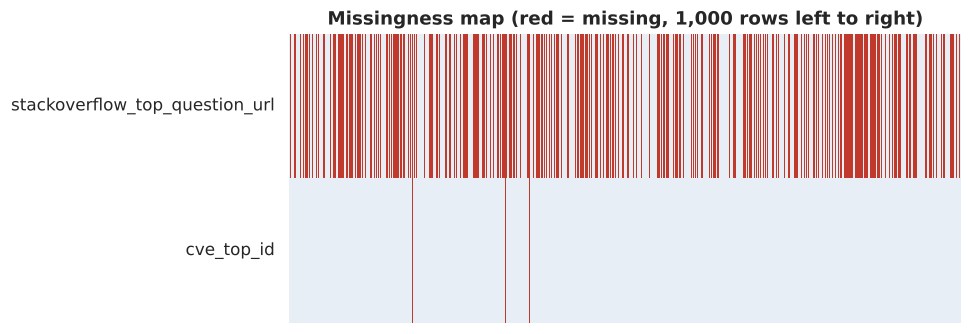

In [12]:
miss = df.drop(columns=["so_url_missing"]).isna().sum()
miss = miss[miss > 0].sort_values(ascending=False)
print("Columns with missing values:")
display(miss.to_frame("missing").assign(**{"missing_%": (miss / len(df) * 100).round(2)}))

fig, ax = plt.subplots(figsize=(9, 3.2))
sns.heatmap(df[["stackoverflow_top_question_url", "cve_top_id"]].isna().T,
            cbar=False, cmap=["#e8eef5", "#c0392b"], yticklabels=True, xticklabels=False, ax=ax)
ax.set_title("Missingness map (red = missing, 1,000 rows left to right)")
plt.tight_layout(); plt.show()

### 3.2 Duplicates, identifier integrity and format validity

In [14]:
ids = df["bug_id"].str.extract(r"BUG_(\d+)")[0].astype(int)
cve = df["cve_top_id"].dropna()
gh_pat = r"^https://github\.com/.+/issues/\d+$"
so_pat = r"^https://stackoverflow\.com/questions/\d+/"
rows = {
    "Fully duplicated rows": int(df_raw.duplicated().sum()),
    "Duplicated bug_id": int(df["bug_id"].duplicated().sum()),
    "bug_id contiguous 1..N": bool((np.sort(ids.values) == np.arange(1, len(df) + 1)).all()),
    "Duplicated cve_top_id (non-null)": int(cve.duplicated().sum()),
    "CVE ids matching CVE-YYYY-NNNN+": f"{cve.str.match(r'^CVE-\d{4}-\d{4,7}$').mean():.1%}",
    "CVE ids with exactly 5-digit sequence": f"{cve.str.match(r'^CVE-\d{4}-\d{5}$').mean():.1%}",
    "GitHub URLs valid": f"{df['github_top_issue_url'].str.match(gh_pat).mean():.1%}",
    "StackOverflow URLs valid (non-null)": f"{df['stackoverflow_top_question_url'].dropna().str.match(so_pat).mean():.1%}",
    "news_latest_date parsed OK": f"{df['news_dt'].notna().mean():.1%}",
}
pd.Series(rows, name="value").to_frame()

,value
Fully duplicated rows,0
Duplicated bug_id,0
bug_id contiguous 1..N,True
Duplicated cve_top_id (non-null),0
CVE ids matching CVE-YYYY-NNNN+,100.0%
CVE ids with exactly 5-digit sequence,90.7%
GitHub URLs valid,100.0%
StackOverflow URLs valid (non-null),100.0%
news_latest_date parsed OK,100.0%


### 3.3 Logical consistency checks

In [16]:
checks = pd.DataFrame({
    "check": [
        "cve_related_count == 0  ->  cve_top_id missing",
        "cve_related_count == 0  ->  severity == 0",
        "stackoverflow_question_count == 0  but a StackOverflow URL is present",
        "stackoverflow_question_count  > 0  but StackOverflow URL is missing",
        "negative stackoverflow_top_answer_score (downvoted answers)",
    ],
    "rows": [
        int(((df.cve_related_count == 0) & df.cve_top_id.isna()).sum()),
        int(((df.cve_related_count == 0) & (df.cve_top_severity_score == 0)).sum()),
        int(((df.stackoverflow_question_count == 0) & ~df.so_url_missing).sum()),
        int(((df.stackoverflow_question_count > 0) & df.so_url_missing).sum()),
        int((df.stackoverflow_top_answer_score < 0).sum()),
    ],
})
checks["of_total_%"] = (checks["rows"] / len(df) * 100).round(1)
display(checks)
print("Cross-tab: question_count == 0 vs StackOverflow URL missing")
pd.crosstab(df.stackoverflow_question_count == 0, df.so_url_missing,
            rownames=["question_count == 0"], colnames=["URL missing"])

Cross-tab: question_count == 0 vs StackOverflow URL missing


,check,rows,of_total_%
0,cve_related_count == 0 -> cve_top_id missing,4,0.4
1,cve_related_count == 0 -> severity == 0,4,0.4
2,stackoverflow_question_count == 0 but a StackOverflow URL is present,33,3.3
3,stackoverflow_question_count > 0 but StackOverflow URL is missing,388,38.8
4,negative stackoverflow_top_answer_score (downvoted answers),96,9.6


URL missing,False,True
question_count == 0,,
False,533,388
True,33,46


## 4 · Univariate analysis — numeric variables

In [18]:
desc = df[NUM_COLS].describe(percentiles=[.05, .25, .5, .75, .95]).T
desc["skew"] = df[NUM_COLS].skew()
desc["kurtosis"] = df[NUM_COLS].kurt()
desc["zeros_%"] = (df[NUM_COLS] == 0).mean() * 100
desc.round(2)

,count,mean,std,min,5%,25%,50%,75%,95%,max,skew,kurtosis,zeros_%
github_similar_issues_count,1000.0,3981.20,4874.82,107.0,107.0,335.00,1094.0,6648.0,17129.00,17129.0,1.44,1.15,0.0
github_top_issue_comments,1000.0,96.62,91.26,0.0,6.0,23.00,47.0,166.0,275.05,299.0,0.82,-0.75,0.9
stackoverflow_question_count,1000.0,4.12,2.88,0.0,0.0,2.00,4.0,6.0,9.00,10.0,0.47,-0.82,7.9
stackoverflow_top_answer_score,1000.0,6.36,6.27,-2.0,-1.0,1.75,4.0,11.0,19.00,20.0,0.70,-0.71,6.6
cve_related_count,1000.0,18.07,13.19,0.0,2.0,7.00,15.0,27.0,44.00,58.0,0.77,-0.23,0.4
cve_top_severity_score,1000.0,6.20,1.94,0.0,3.3,4.50,6.2,7.9,9.10,9.5,-0.06,-0.98,0.4
news_related_count,1000.0,1213.76,1257.61,146.0,146.0,335.00,640.0,2003.0,4829.00,4829.0,1.56,1.68,0.0


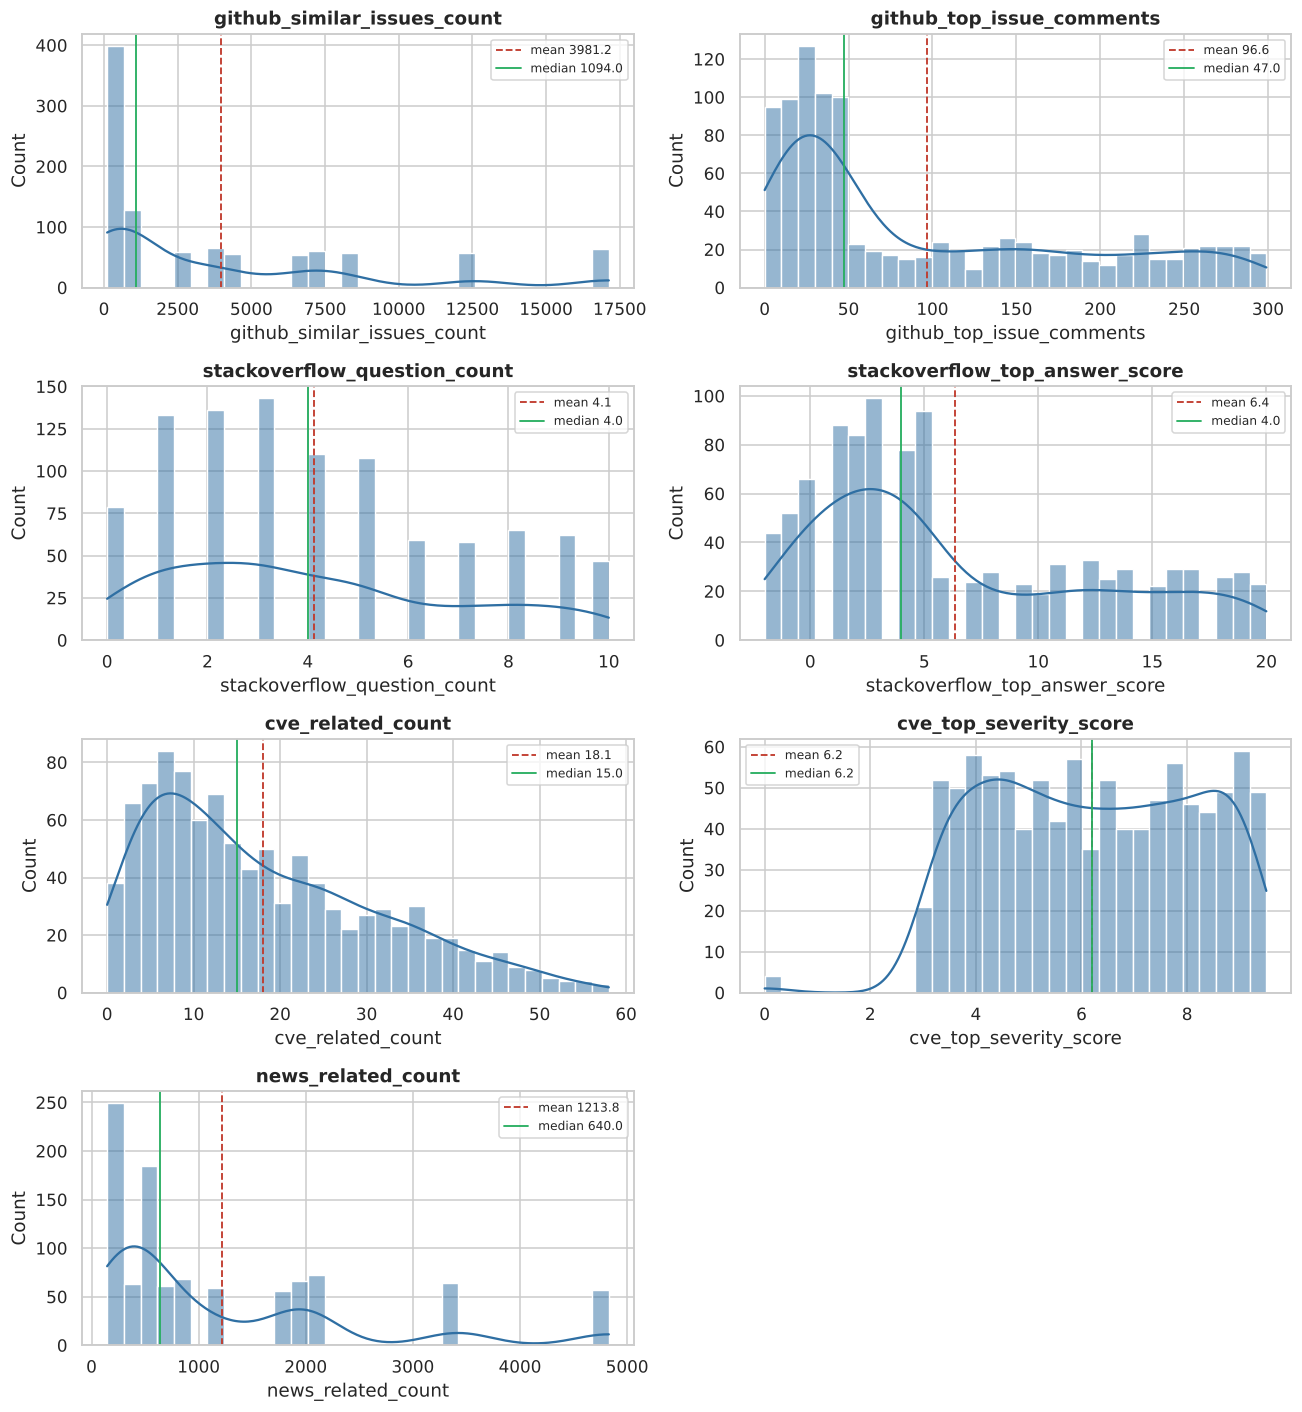

In [19]:
fig, axes = plt.subplots(4, 2, figsize=(12, 13))
for ax, col in zip(axes.ravel(), NUM_COLS):
    sns.histplot(df[col], bins=30, kde=True, ax=ax, color="#2f6fa3")
    ax.axvline(df[col].mean(), color="#c0392b", ls="--", lw=1.2, label=f"mean {df[col].mean():.1f}")
    ax.axvline(df[col].median(), color="#27ae60", ls="-", lw=1.2, label=f"median {df[col].median():.1f}")
    ax.set_title(col); ax.legend(fontsize=8)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

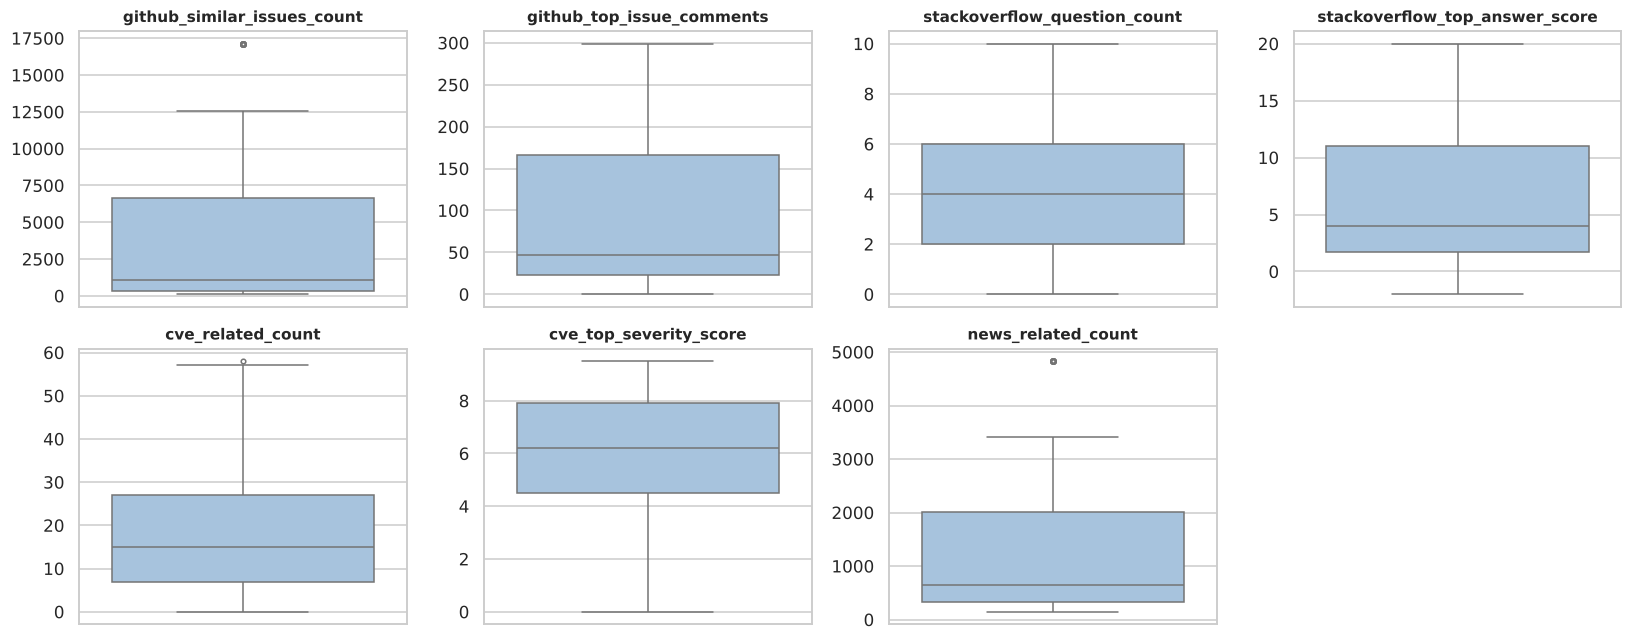

In [20]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, col in zip(axes.ravel(), NUM_COLS):
    sns.boxplot(y=df[col], ax=ax, color="#9ec3e6", fliersize=3)
    ax.set_title(col, fontsize=10); ax.set_ylabel("")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

### 4.1 Outliers (Tukey 1.5 × IQR rule)

In [22]:
rows = []
for c in NUM_COLS:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_lo, n_hi = int((df[c] < lo).sum()), int((df[c] > hi).sum())
    rows.append({"column": c, "lower_fence": round(lo, 2), "upper_fence": round(hi, 2),
                 "n_low": n_lo, "n_high": n_hi, "outlier_%": round((n_lo + n_hi) / len(df) * 100, 1)})
pd.DataFrame(rows).set_index("column")

,lower_fence,upper_fence,n_low,n_high,outlier_%
column,,,,,
github_similar_issues_count,-9134.50,16117.50,0,64,6.4
github_top_issue_comments,-191.50,380.50,0,0,0.0
stackoverflow_question_count,-4.00,12.00,0,0,0.0
stackoverflow_top_answer_score,-12.12,24.88,0,0,0.0
cve_related_count,-23.00,57.00,0,1,0.1
cve_top_severity_score,-0.60,13.00,0,0,0.0
news_related_count,-2167.00,4505.00,0,57,5.7


### 4.2 Normality (Shapiro–Wilk) — decides whether to use Pearson or Spearman later

In [24]:
rows = []
for c in NUM_COLS:
    w, p = stats.shapiro(df[c])
    rows.append({"column": c, "W": round(w, 4), "p_value": p, "normal_at_5%": p > 0.05,
                 "skew": round(df[c].skew(), 2)})
pd.DataFrame(rows).set_index("column")

,W,p_value,normal_at_5%,skew
column,,,,
github_similar_issues_count,0.7597,8.602169e-36,False,1.44
github_top_issue_comments,0.8435,2.908168e-30,False,0.82
stackoverflow_question_count,0.9340,1.328344e-20,False,0.47
stackoverflow_top_answer_score,0.9039,1.437939e-24,False,0.70
cve_related_count,0.9294,2.714148e-21,False,0.77
cve_top_severity_score,0.9549,5.703774e-17,False,-0.06
news_related_count,0.7655,1.830762e-35,False,1.56


## 5 · Univariate analysis — categorical variables

Largest bug type : UI Bug (8.1%);  smallest: Performance Bug (4.6%)
Chi-square test vs uniform distribution of bug types: chi2=17.0, p=0.3193


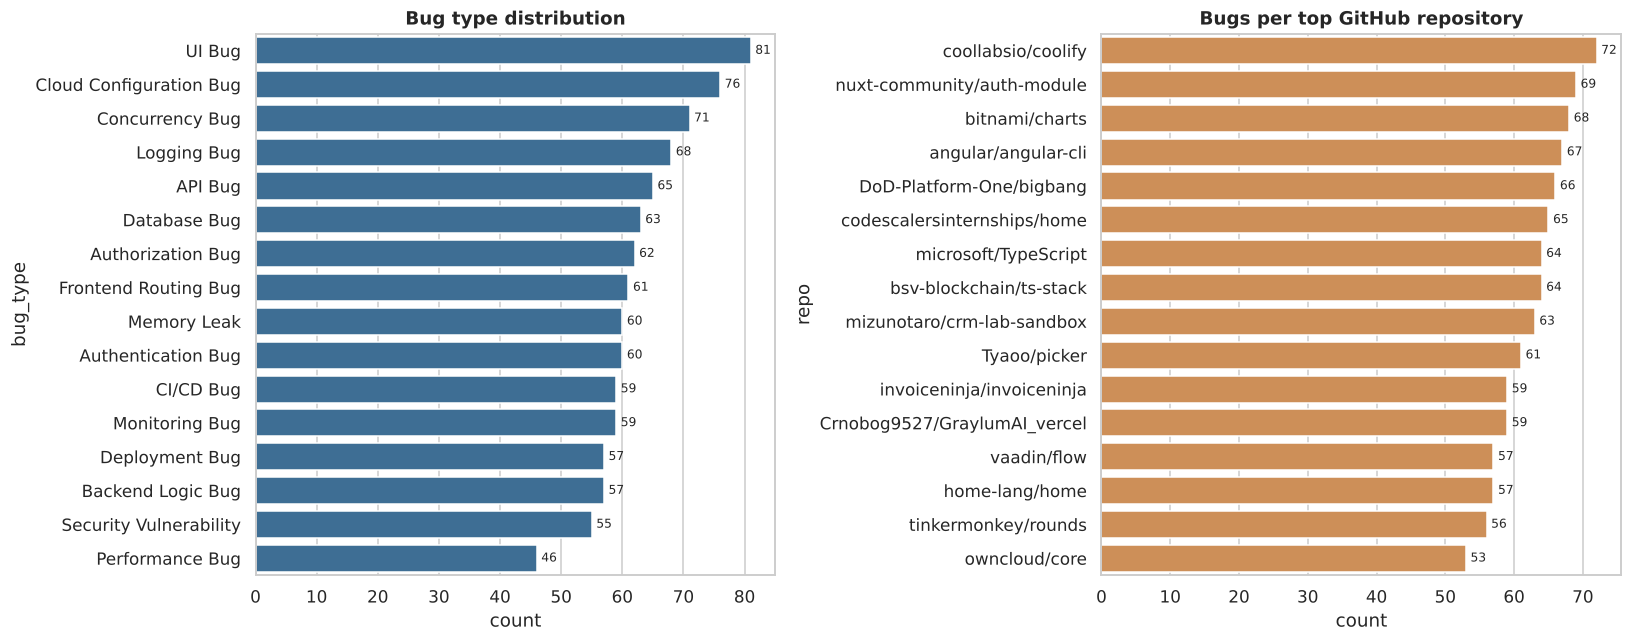

In [26]:
def annotate_bars(ax):
    for p in ax.patches:
        ax.annotate(f"{int(p.get_width())}", (p.get_width(), p.get_y() + p.get_height() / 2),
                    xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.countplot(y="bug_type", data=df, order=df["bug_type"].value_counts().index, ax=axes[0], color="#2f6fa3")
axes[0].set_title("Bug type distribution"); annotate_bars(axes[0])
sns.countplot(y="repo", data=df, order=df["repo"].value_counts().index, ax=axes[1], color="#e08e45")
axes[1].set_title("Bugs per top GitHub repository"); annotate_bars(axes[1])
plt.tight_layout(); plt.show()

share = df["bug_type"].value_counts(normalize=True)
print(f"Largest bug type : {share.index[0]} ({share.iloc[0]:.1%});  smallest: {share.index[-1]} ({share.iloc[-1]:.1%})")
chi2, p = stats.chisquare(df["bug_type"].value_counts())
print(f"Chi-square test vs uniform distribution of bug types: chi2={chi2:.1f}, p={p:.4f}")

In [27]:
cat_cols = ["bug_type", "repo", "stackoverflow_top_question_url", "news_latest_title", "news_latest_date"]
card = pd.DataFrame({
    "unique": df[cat_cols].nunique(),
    "top_value": [str(df[c].mode()[0])[:60] for c in cat_cols],
    "top_freq": [df[c].value_counts().iloc[0] for c in cat_cols],
})
card

,unique,top_value,top_freq
bug_type,16,UI Bug,81
repo,16,coollabsio/coolify,72
stackoverflow_top_question_url,9,https://stackoverflow.com/questions/63712861/fail-to-deploy-,72
news_latest_title,15,baucli 1.0.112,112
news_latest_date,15,2026-08-29T20:26:24Z,112


## 6 · Hierarchy check — which columns are really *per-bug* and which are *per-repository*?
The columns come from different enrichment APIs. If a column has exactly one value per repository, it carries repository-level information, not bug-level information. That matters a lot for modelling.

In [29]:
cols = ["github_similar_issues_count", "github_top_issue_url", "news_related_count", "news_latest_title",
        "news_latest_date", "stackoverflow_top_question_url", "cve_related_count",
        "github_top_issue_comments", "stackoverflow_question_count", "stackoverflow_top_answer_score",
        "cve_top_severity_score"]
per_repo = df.groupby("repo")[cols].nunique()
summary = pd.DataFrame({
    "max_distinct_values_within_one_repo": per_repo.max(),
    "level": np.where(per_repo.max() <= 1, "constant per repo (repo-level attribute)", "varies within repo (bug-level)"),
})
summary

,max_distinct_values_within_one_repo,level
github_similar_issues_count,1,constant per repo (repo-level attribute)
github_top_issue_url,1,constant per repo (repo-level attribute)
news_related_count,1,constant per repo (repo-level attribute)
news_latest_title,1,constant per repo (repo-level attribute)
news_latest_date,1,constant per repo (repo-level attribute)
stackoverflow_top_question_url,1,constant per repo (repo-level attribute)
cve_related_count,38,varies within repo (bug-level)
github_top_issue_comments,65,varies within repo (bug-level)
stackoverflow_question_count,10,varies within repo (bug-level)
stackoverflow_top_answer_score,21,varies within repo (bug-level)


In [30]:
repo_tbl = (df.groupby("repo")
              .agg(bugs=("bug_id", "size"),
                   github_similar_issues=("github_similar_issues_count", "first"),
                   news_related=("news_related_count", "first"),
                   news_latest_title=("news_latest_title", "first"),
                   so_url_available=("stackoverflow_top_question_url", lambda s: s.notna().any()),
                   so_url_missing_pct=("so_url_missing", lambda s: round(s.mean() * 100, 1)),
                   mean_cve_count=("cve_related_count", "mean"),
                   mean_severity=("cve_top_severity_score", "mean"))
              .round(2).sort_values("github_similar_issues", ascending=False))
repo_tbl

,bugs,github_similar_issues,news_related,news_latest_title,so_url_available,so_url_missing_pct,mean_cve_count,mean_severity
repo,,,,,,,,
microsoft/TypeScript,64,17129,3421,pyspark-tools 0.0.8,False,100.0,31.97,5.95
home-lang/home,57,12581,4829,"Tina Arena, the 'worst album ever made', and more music doco highlights",False,100.0,7.23,5.70
vaadin/flow,57,8247,186,How a freshman elevated to starting placekicker for Purdue football,True,0.0,27.72,6.23
Tyaoo/picker,61,7124,640,age v1.3.2,False,100.0,18.82,6.56
owncloud/core,53,6648,487,baucli 1.0.112,True,0.0,32.09,6.49
tinkermonkey/rounds,56,4105,1786,whycache added to PyPI,False,100.0,19.91,6.09
DoD-Platform-One/bigbang,66,3583,2003,azath 0.1.0,True,0.0,20.62,6.46
Crnobog9527/GraylumAI_vercel,59,2894,1204,baucli 1.0.112,True,0.0,26.93,6.44
mizunotaro/crm-lab-sandbox,63,1094,335,prema-agentshield added to PyPI,False,100.0,16.54,6.41


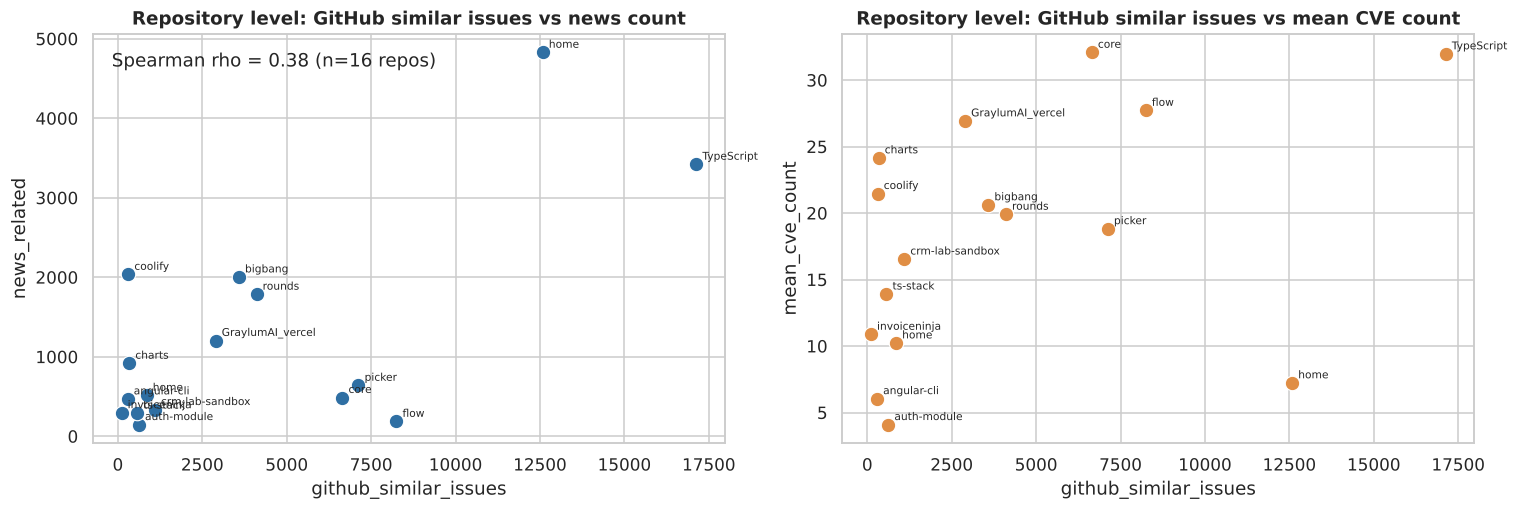

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.scatterplot(data=repo_tbl, x="github_similar_issues", y="news_related", s=90, ax=axes[0], color="#2f6fa3")
for name, r in repo_tbl.iterrows():
    axes[0].annotate(name.split("/")[-1], (r.github_similar_issues, r.news_related), fontsize=7, xytext=(4, 3), textcoords="offset points")
axes[0].set_title("Repository level: GitHub similar issues vs news count")
rho, p = stats.spearmanr(repo_tbl.github_similar_issues, repo_tbl.news_related)
axes[0].text(0.03, 0.92, f"Spearman rho = {rho:.2f} (n=16 repos)", transform=axes[0].transAxes)
sns.scatterplot(data=repo_tbl, x="github_similar_issues", y="mean_cve_count", s=90, ax=axes[1], color="#e08e45")
for name, r in repo_tbl.iterrows():
    axes[1].annotate(name.split("/")[-1], (r.github_similar_issues, r.mean_cve_count), fontsize=7, xytext=(4, 3), textcoords="offset points")
axes[1].set_title("Repository level: GitHub similar issues vs mean CVE count")
plt.tight_layout(); plt.show()

## 7 · Missingness deep-dive: StackOverflow URL and CVE id

Repos with NO StackOverflow URL at all: 7 -> 434 missing rows
Missing rows inside repos that do have a URL: 0


,bugs,missing,missing_rate
repo,,,
Tyaoo/picker,61,61,1.0
bsv-blockchain/ts-stack,64,64,1.0
microsoft/TypeScript,64,64,1.0
tinkermonkey/rounds,56,56,1.0
nuxt-community/auth-module,69,69,1.0
mizunotaro/crm-lab-sandbox,63,63,1.0
home-lang/home,57,57,1.0
DoD-Platform-One/bigbang,66,0,0.0
coollabsio/coolify,72,0,0.0


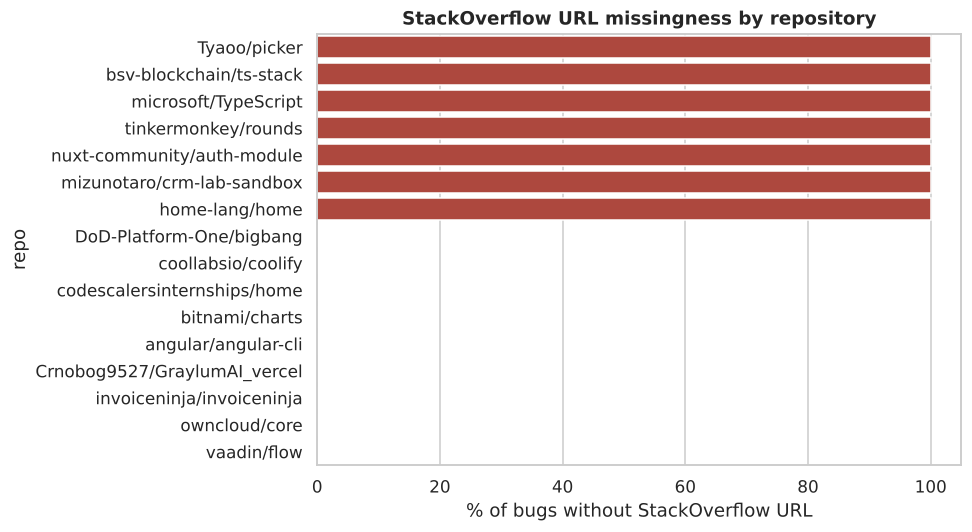

In [33]:
so = (df.groupby("repo")["so_url_missing"].agg(["size", "sum", "mean"])
        .rename(columns={"size": "bugs", "sum": "missing", "mean": "missing_rate"})
        .sort_values("missing_rate", ascending=False))
display(so.round(3))
repos_without_url = so.index[so["missing_rate"] == 1].tolist()
print(f"Repos with NO StackOverflow URL at all: {len(repos_without_url)} -> {int(so.loc[repos_without_url, 'missing'].sum())} missing rows")
print(f"Missing rows inside repos that do have a URL: {int(so.loc[so.missing_rate < 1, 'missing'].sum())}")

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=so["missing_rate"] * 100, y=so.index, color="#c0392b", ax=ax)
ax.set_xlabel("% of bugs without StackOverflow URL"); ax.set_title("StackOverflow URL missingness by repository")
plt.tight_layout(); plt.show()

In [34]:
# Is the missingness related to the numeric fields? (Mann-Whitney U, missing vs present)
rows = []
for c in NUM_COLS:
    a = df.loc[df.so_url_missing, c]; b = df.loc[~df.so_url_missing, c]
    u, p = stats.mannwhitneyu(a, b)
    rows.append({"column": c, "median_missing": a.median(), "median_present": b.median(), "p_value": round(p, 5), "significant_5%": p < .05})
display(pd.DataFrame(rows).set_index("column"))

ct = pd.crosstab(df.bug_type, df.so_url_missing)
chi2, p, dof, _ = stats.chi2_contingency(ct)
print(f"Chi-square, bug_type vs URL missing: chi2={chi2:.2f}, dof={dof}, p={p:.4f}")
print("\nRows with no CVE id (CVE count is 0, so this is 'no CVE found', not a data error):")
df.loc[df.cve_top_id.isna(), ["bug_id", "bug_type", "repo", "cve_related_count", "cve_top_severity_score"]]

Chi-square, bug_type vs URL missing: chi2=19.52, dof=15, p=0.1909

Rows with no CVE id (CVE count is 0, so this is 'no CVE found', not a data error):


,median_missing,median_present,p_value,significant_5%
column,,,,
github_similar_issues_count,4105.0,851.0,0.00000,True
github_top_issue_comments,36.5,86.5,0.00000,True
stackoverflow_question_count,3.0,4.0,0.00011,True
stackoverflow_top_answer_score,3.0,5.0,0.00000,True
cve_related_count,12.0,17.0,0.00000,True
cve_top_severity_score,6.1,6.2,0.53390,False
news_related_count,640.0,513.0,0.81612,False


,bug_id,bug_type,repo,cve_related_count,cve_top_severity_score
183,BUG_000184,UI Bug,nuxt-community/auth-module,0,0.0
321,BUG_000322,Authorization Bug,nuxt-community/auth-module,0,0.0
357,BUG_000358,Frontend Routing Bug,nuxt-community/auth-module,0,0.0
679,BUG_000680,Security Vulnerability,nuxt-community/auth-module,0,0.0


## 8 · Bivariate and multivariate analysis

### 8.1 Correlation structure (Pearson and Spearman)

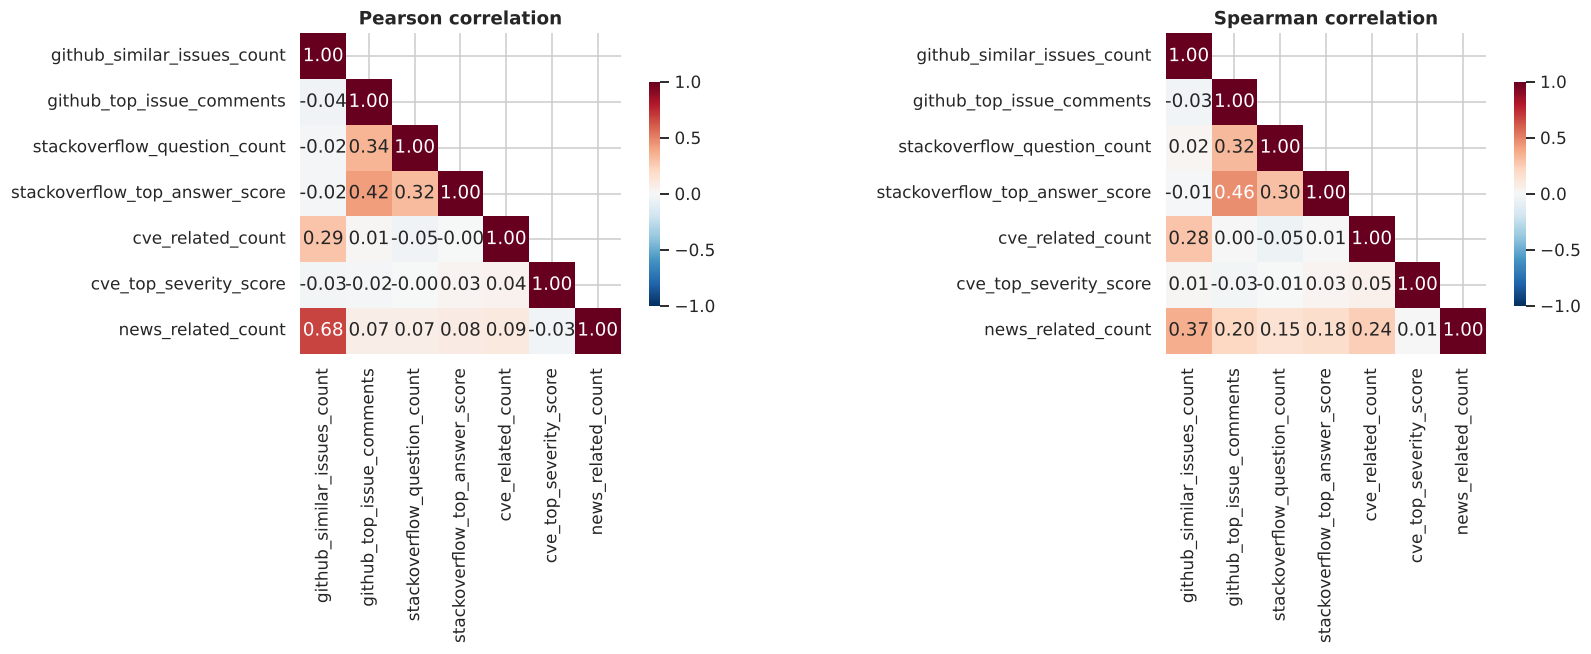

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, m in zip(axes, ["pearson", "spearman"]):
    c = df[NUM_COLS].corr(method=m)
    sns.heatmap(c, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
                mask=np.triu(np.ones_like(c, dtype=bool), k=1), cbar_kws={"shrink": .7}, ax=ax)
    ax.set_title(f"{m.title()} correlation")
plt.tight_layout(); plt.show()

In [38]:
pairs = []
for i, a in enumerate(NUM_COLS):
    for b in NUM_COLS[i + 1:]:
        r, p = stats.spearmanr(df[a], df[b])
        pairs.append({"var_1": a, "var_2": b, "spearman_rho": round(r, 3), "p_value": p,
                      "strength": "strong" if abs(r) >= .6 else "moderate" if abs(r) >= .3 else "weak/none"})
pairs = pd.DataFrame(pairs)
pairs = pairs.reindex(pairs.spearman_rho.abs().sort_values(ascending=False).index)
pairs.head(10).reset_index(drop=True)

,var_1,var_2,spearman_rho,p_value,strength
0,github_top_issue_comments,stackoverflow_top_answer_score,0.463,2.697920e-54,moderate
1,github_similar_issues_count,news_related_count,0.365,6.049769e-33,moderate
2,github_top_issue_comments,stackoverflow_question_count,0.322,1.482235e-25,moderate
3,stackoverflow_question_count,stackoverflow_top_answer_score,0.303,1.296994e-22,moderate
4,github_similar_issues_count,cve_related_count,0.282,9.498295e-20,weak/none
5,cve_related_count,news_related_count,0.243,6.783558e-15,weak/none
6,github_top_issue_comments,news_related_count,0.203,8.469888e-11,weak/none
7,stackoverflow_top_answer_score,news_related_count,0.176,1.998049e-08,weak/none
8,stackoverflow_question_count,news_related_count,0.149,2.184309e-06,weak/none
9,cve_related_count,cve_top_severity_score,0.054,8.699504e-02,weak/none


### 8.2 Key relationships

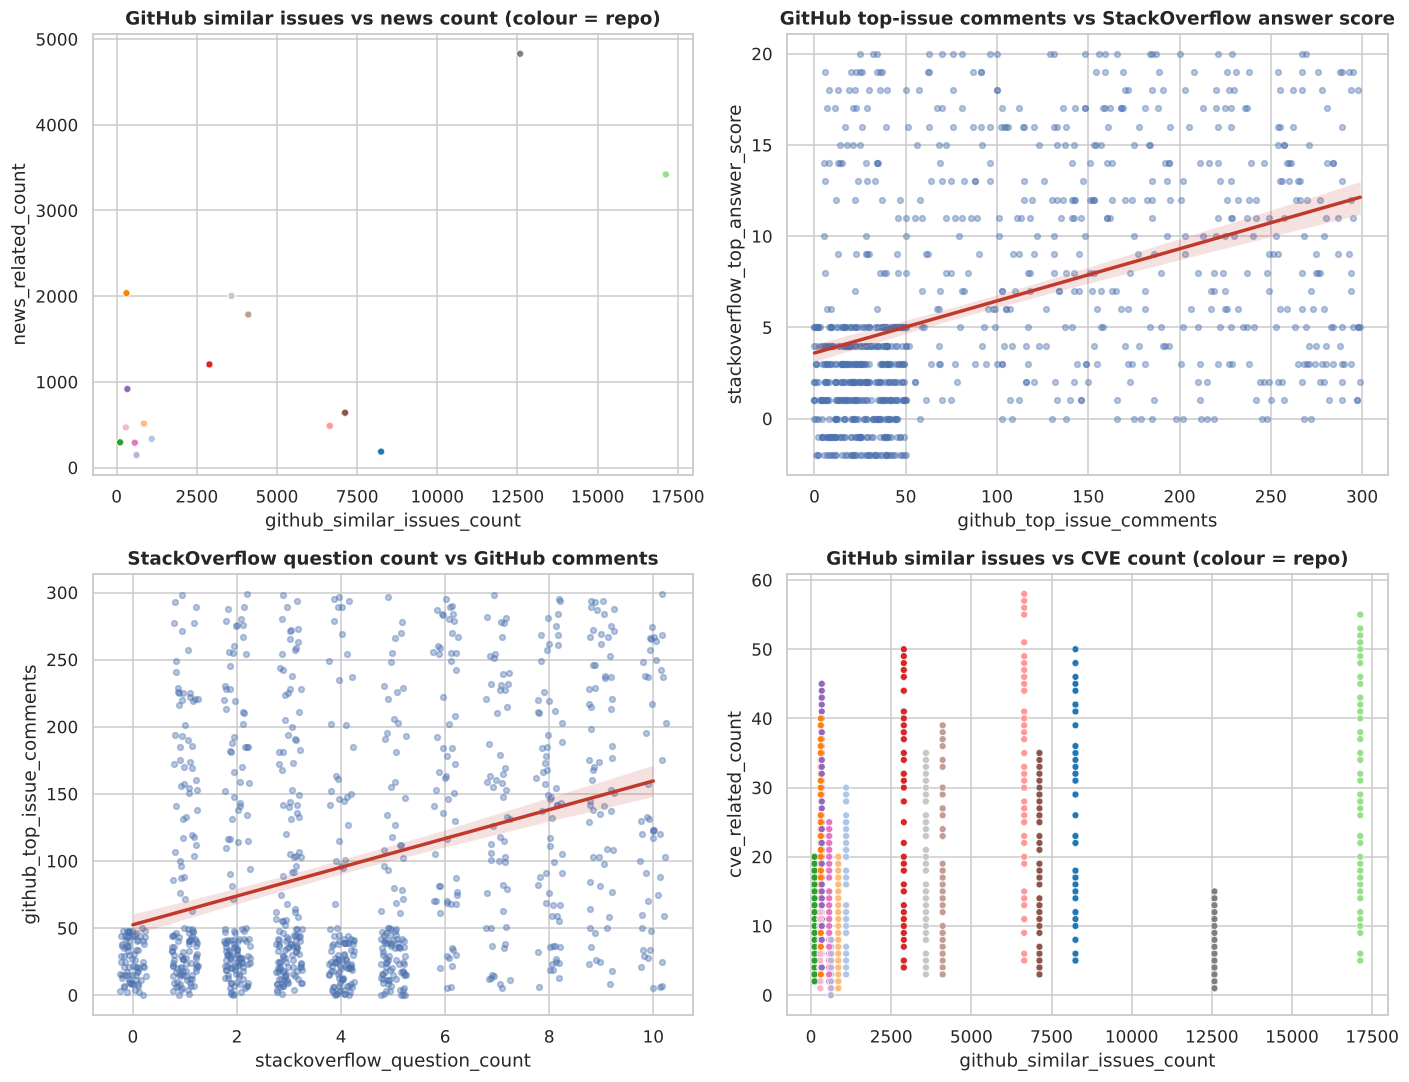

In [40]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
sns.scatterplot(data=df, x="github_similar_issues_count", y="news_related_count", hue="repo", legend=False, s=20, ax=axes[0, 0], palette="tab20")
axes[0, 0].set_title("GitHub similar issues vs news count (colour = repo)")
sns.regplot(data=df, x="github_top_issue_comments", y="stackoverflow_top_answer_score", scatter_kws={"s": 14, "alpha": .4}, line_kws={"color": "#c0392b"}, ax=axes[0, 1])
axes[0, 1].set_title("GitHub top-issue comments vs StackOverflow answer score")
sns.regplot(data=df, x="stackoverflow_question_count", y="github_top_issue_comments", x_jitter=.25, scatter_kws={"s": 14, "alpha": .4}, line_kws={"color": "#c0392b"}, ax=axes[1, 0])
axes[1, 0].set_title("StackOverflow question count vs GitHub comments")
sns.scatterplot(data=df, x="github_similar_issues_count", y="cve_related_count", hue="repo", legend=False, s=20, ax=axes[1, 1], palette="tab20")
axes[1, 1].set_title("GitHub similar issues vs CVE count (colour = repo)")
plt.tight_layout(); plt.show()

### 8.3 Pairplot of all numeric features

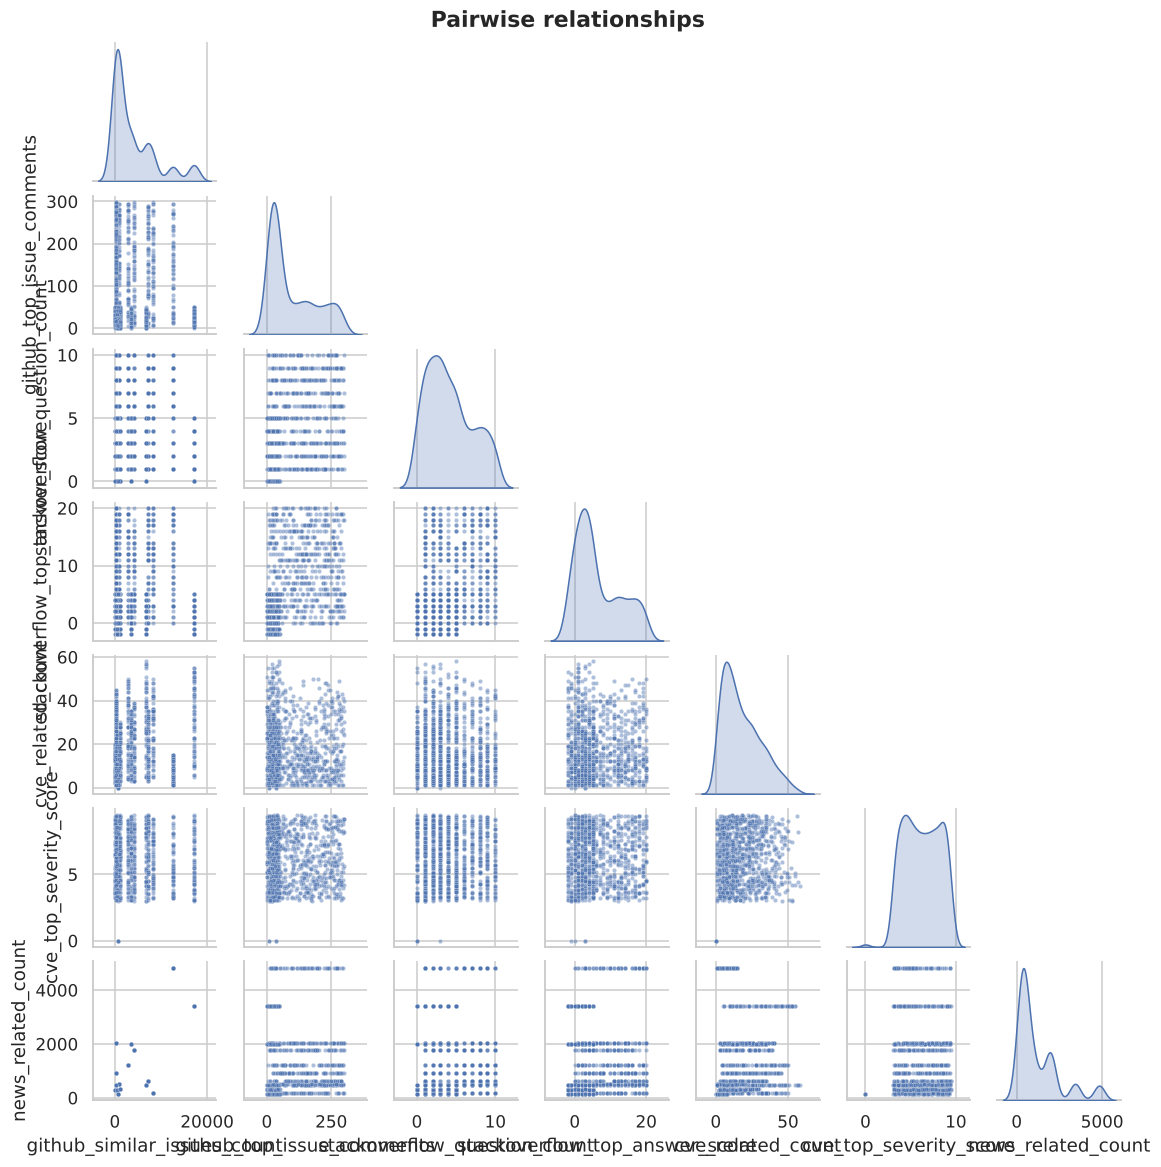

In [42]:
g = sns.pairplot(df[NUM_COLS], corner=True, plot_kws={"s": 8, "alpha": .45}, diag_kind="kde", height=1.5)
g.fig.suptitle("Pairwise relationships", y=1.01, fontweight="bold")
plt.show()

## 9 · Group analysis by bug type

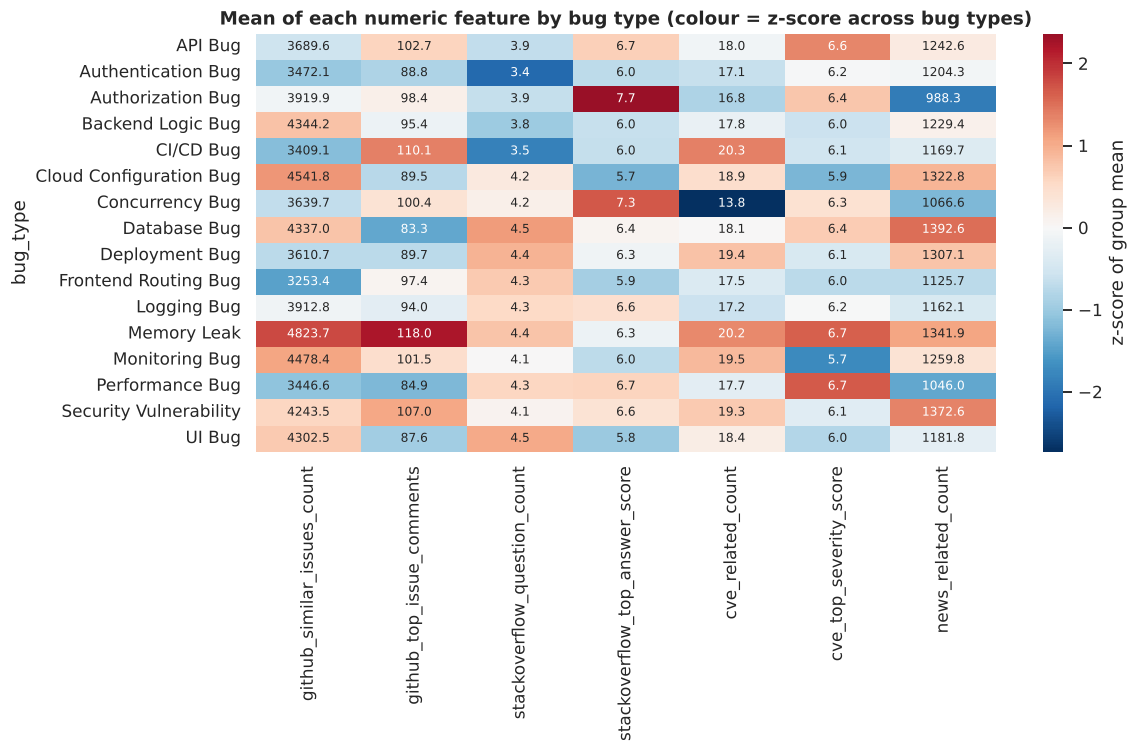

In [44]:
grp = df.groupby("bug_type")[NUM_COLS].mean()
z = (grp - grp.mean()) / grp.std()
fig, ax = plt.subplots(figsize=(11, 7))
sns.heatmap(z, annot=grp.round(1), fmt="", cmap="RdBu_r", center=0, cbar_kws={"label": "z-score of group mean"}, ax=ax, annot_kws={"size": 8})
ax.set_title("Mean of each numeric feature by bug type (colour = z-score across bug types)")
plt.tight_layout(); plt.show()

In [45]:
rows = []
for c in NUM_COLS:
    groups = [g[c].values for _, g in df.groupby("bug_type")]
    h, p = stats.kruskal(*groups)
    n, k = len(df), len(groups)
    eps2 = (h - k + 1) / (n - k)          # epsilon-squared effect size
    rows.append({"feature": c, "H": round(h, 2), "p_value": round(p, 4), "effect_eps2": round(max(eps2, 0), 4),
                 "differs_by_bug_type_5%": p < .05})
pd.DataFrame(rows).set_index("feature")

,H,p_value,effect_eps2,differs_by_bug_type_5%
feature,,,,
github_similar_issues_count,14.59,0.4812,0.0000,False
github_top_issue_comments,9.32,0.8601,0.0000,False
stackoverflow_question_count,10.51,0.7863,0.0000,False
stackoverflow_top_answer_score,7.51,0.9418,0.0000,False
cve_related_count,20.61,0.1498,0.0057,False
cve_top_severity_score,19.19,0.2052,0.0043,False
news_related_count,11.57,0.7116,0.0000,False


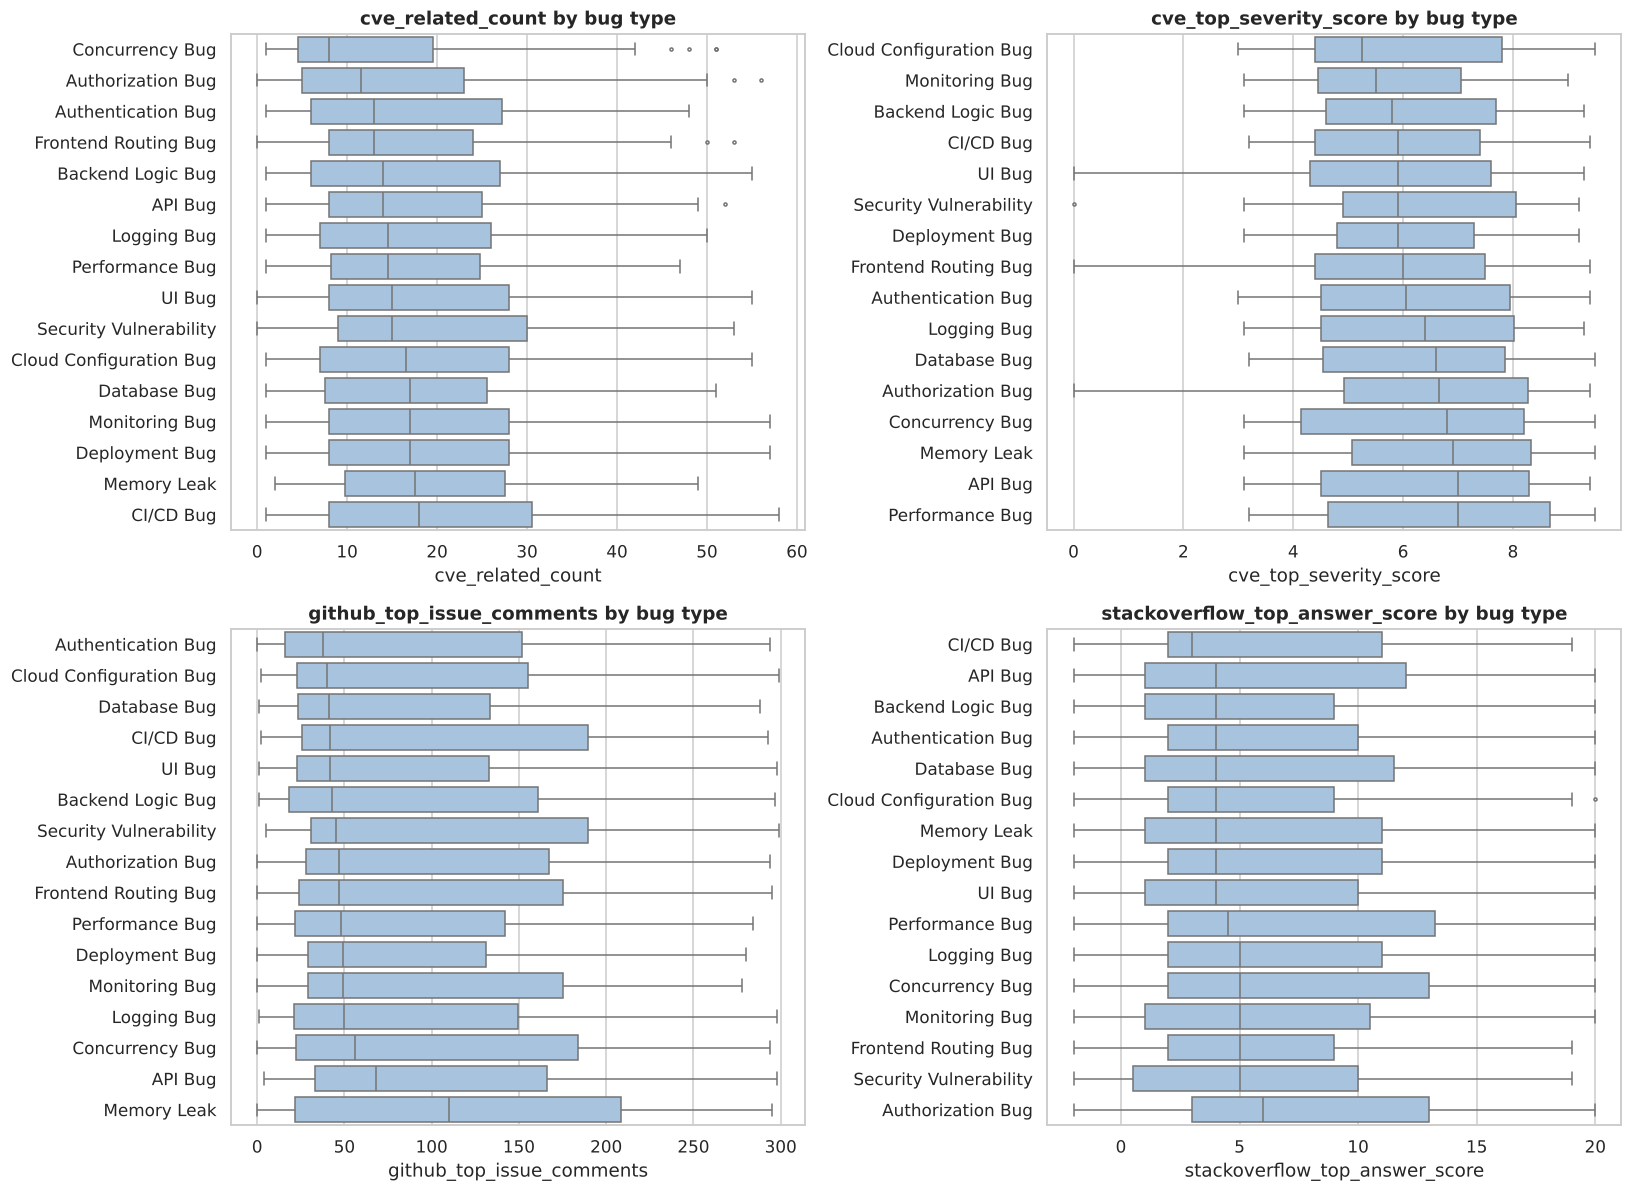

In [46]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
for ax, c in zip(axes.ravel(), ["cve_related_count", "cve_top_severity_score", "github_top_issue_comments", "stackoverflow_top_answer_score"]):
    order = df.groupby("bug_type")[c].median().sort_values().index
    sns.boxplot(data=df, y="bug_type", x=c, order=order, ax=ax, color="#9ec3e6", fliersize=2)
    ax.set_title(f"{c} by bug type"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

### 9.1 Group analysis by repository

,H,p_value,effect_eps2,differs_by_repo_5%
feature,,,,
cve_related_count,446.5,1.136484e-85,0.438,True
cve_top_severity_score,25.7,4.099518e-02,0.011,True
github_top_issue_comments,517.4,1.199526e-100,0.511,True
stackoverflow_question_count,252.8,3.242440e-45,0.242,True
stackoverflow_top_answer_score,462.3,5.331800e-89,0.455,True


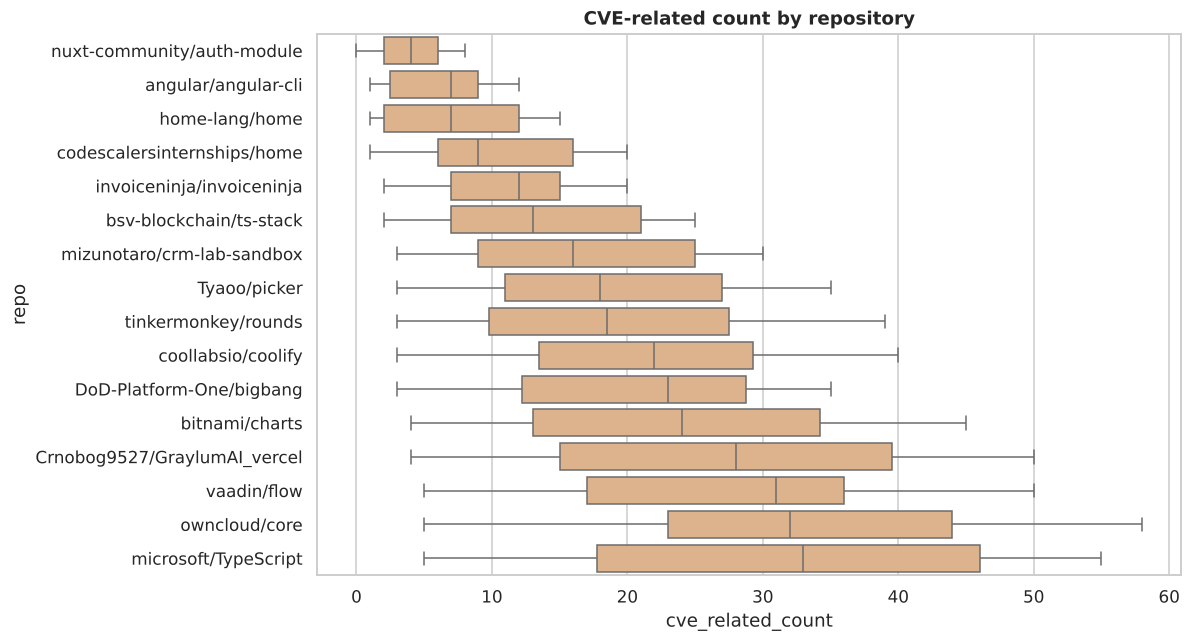

In [48]:
rows = []
for c in ["cve_related_count", "cve_top_severity_score", "github_top_issue_comments", "stackoverflow_question_count", "stackoverflow_top_answer_score"]:
    groups = [g[c].values for _, g in df.groupby("repo")]
    h, p = stats.kruskal(*groups)
    k, n = len(groups), len(df)
    rows.append({"feature": c, "H": round(h, 1), "p_value": p, "effect_eps2": round(max((h - k + 1) / (n - k), 0), 3),
                 "differs_by_repo_5%": p < .05})
display(pd.DataFrame(rows).set_index("feature"))

order = df.groupby("repo")["cve_related_count"].median().sort_values().index
fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(data=df, y="repo", x="cve_related_count", order=order, color="#e9b27f", ax=ax, fliersize=2)
ax.set_title("CVE-related count by repository")
plt.tight_layout(); plt.show()

## 10 · Severity and CVE analysis

Low (0-3.9)        14.7 %
Medium (4-6.9)     46.2 %
High (7-8.9)       30.4 %
Critical (9-10)     8.7 %
Name: count, dtype: str

Spearman(CVE year, severity) = 0.006, p = 0.860


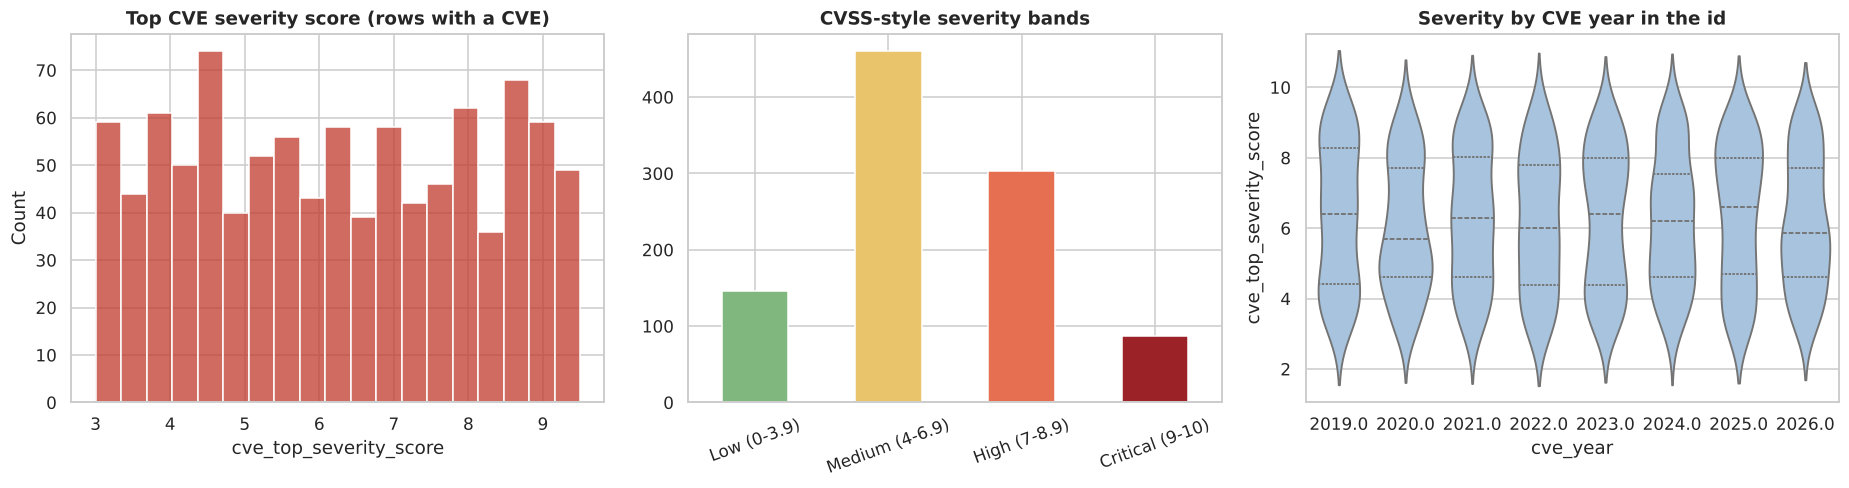

In [50]:
cve_rows = df[df.cve_related_count > 0].copy()
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
sns.histplot(cve_rows.cve_top_severity_score, bins=19, ax=axes[0], color="#c0392b")
axes[0].set_title("Top CVE severity score (rows with a CVE)")
bands = pd.cut(cve_rows.cve_top_severity_score, [-0.01, 3.9, 6.9, 8.9, 10],
               labels=["Low (0-3.9)", "Medium (4-6.9)", "High (7-8.9)", "Critical (9-10)"])
band_counts = bands.value_counts().reindex(bands.cat.categories)
band_counts.plot.bar(ax=axes[1], color=["#7fb77e", "#e9c46a", "#e76f51", "#9b2226"], rot=20)
axes[1].set_title("CVSS-style severity bands")
sns.violinplot(data=df, x="cve_year", y="cve_top_severity_score", ax=axes[2], color="#9ec3e6", inner="quartile")
axes[2].set_title("Severity by CVE year in the id")
plt.tight_layout(); plt.show()

print((band_counts / band_counts.sum() * 100).round(1).astype(str) + " %")
ok = cve_rows.dropna(subset=["cve_year"])
rho, p = stats.spearmanr(ok.cve_year, ok.cve_top_severity_score)
print(f"\nSpearman(CVE year, severity) = {rho:.3f}, p = {p:.3f}")

## 11 · Temporal analysis

News timestamp range: 2026-08-28 16:45:20+00:00 -> 2026-08-29 21:06:30+00:00
Distinct news timestamps: 15 | span: 1 days 04:21:10
Share of bugs whose CVE id is from 2026: 12.4%


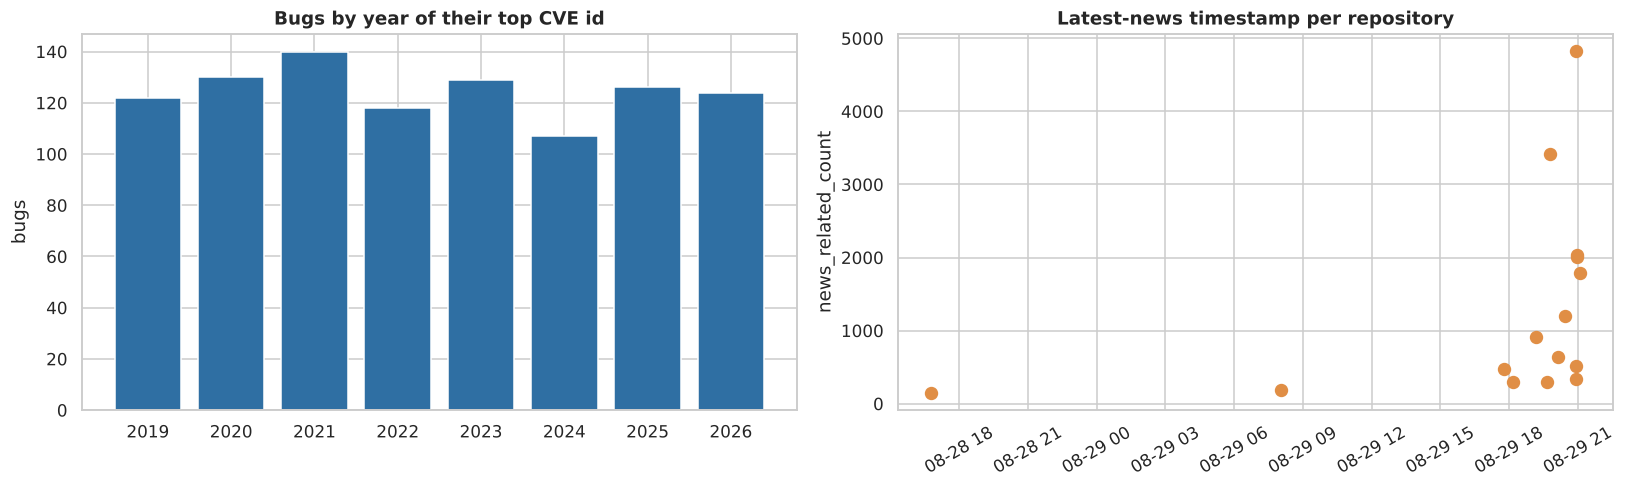

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
yr = df["cve_year"].value_counts().sort_index()
axes[0].bar(yr.index.astype(int).astype(str), yr.values, color="#2f6fa3")
axes[0].set_title("Bugs by year of their top CVE id"); axes[0].set_ylabel("bugs")

nd = df.drop_duplicates("news_dt").sort_values("news_dt")
axes[1].scatter(nd.news_dt, nd.news_related_count, s=60, color="#e08e45")
axes[1].set_title("Latest-news timestamp per repository")
axes[1].set_ylabel("news_related_count"); axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

print("News timestamp range:", df.news_dt.min(), "->", df.news_dt.max())
print("Distinct news timestamps:", df.news_dt.nunique(), "| span:", df.news_dt.max() - df.news_dt.min())
print(f"Share of bugs whose CVE id is from 2026: {(df.cve_year == 2026).mean():.1%}")

## 12 · News relevance check

In [54]:
news = (df.groupby("news_latest_title")
          .agg(rows=("bug_id", "size"), repos=("repo", "nunique"), news_related_count=("news_related_count", "first"))
          .sort_values("rows", ascending=False))
news

,rows,repos,news_related_count
news_latest_title,,,
baucli 1.0.112,112,2,1204
django-todo 2.7.0,72,1,2036
Laravel Starter Kits Now Ship with Vite+,69,1,146
conduit-client added to PyPI,68,1,917
DoYeon Kim – Wellspring (2026),67,1,469
azath 0.1.0,66,1,2003
loomtrace added to PyPI,65,1,513
pyspark-tools 0.0.8,64,1,3421
tag-query 1.2.1,64,1,290


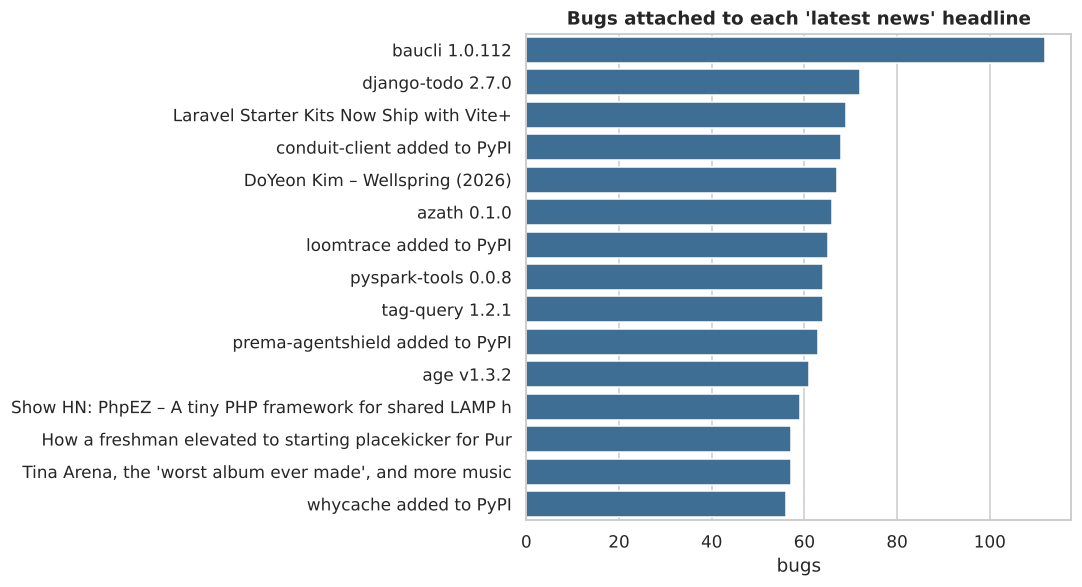

In [55]:
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(x=news.rows, y=news.index.str.slice(0, 55), color="#2f6fa3", ax=ax)
ax.set_title("Bugs attached to each 'latest news' headline"); ax.set_xlabel("bugs"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

## 13 · Redundancy and feature-set diagnostics

In [57]:
Xs = (df[NUM_COLS] - df[NUM_COLS].mean()) / df[NUM_COLS].std()
vif = pd.Series(np.diag(np.linalg.inv(np.corrcoef(Xs.values.T))), index=NUM_COLS, name="VIF").round(2)
print("Variance Inflation Factors (>5 suggests multicollinearity):")
vif.to_frame()

Variance Inflation Factors (>5 suggests multicollinearity):


,VIF
github_similar_issues_count,2.09
github_top_issue_comments,1.30
stackoverflow_question_count,1.19
stackoverflow_top_answer_score,1.27
cve_related_count,1.12
cve_top_severity_score,1.01
news_related_count,1.94


In [58]:
# How much of each numeric feature's variance is explained by repository membership alone? (eta-squared)
rows = []
for c in NUM_COLS:
    gm = df[c].mean()
    ssb = sum(len(g) * (g[c].mean() - gm) ** 2 for _, g in df.groupby("repo"))
    sst = ((df[c] - gm) ** 2).sum()
    rows.append({"feature": c, "variance_explained_by_repo_%": round(ssb / sst * 100, 1)})
pd.DataFrame(rows).set_index("feature").sort_values("variance_explained_by_repo_%", ascending=False)

,variance_explained_by_repo_%
feature,
github_similar_issues_count,100.0
news_related_count,100.0
github_top_issue_comments,48.2
stackoverflow_top_answer_score,44.2
cve_related_count,43.1
stackoverflow_question_count,27.7
cve_top_severity_score,2.5



## 14 · Summary of findings

### Dataset at a glance
- **1,000 bugs × 14 columns** after dropping the three `gemini_*` columns (they were not empty: 0 missing, so the drop was done on request, not because of missing data). No duplicate rows; `bug_id` is contiguous (BUG_000001–BUG_001000).
- Bug types are evenly spread over 16 categories (4.6 % – 8.1 % each; chi-square vs uniform p = 0.32).

### Data-quality findings
| # | Finding | Evidence |
|---|---------|----------|
| 1 | **StackOverflow URL is 43.4 % missing** (434 rows) | It is missing for *all* rows of exactly 7 repos and for *none* of the other 9. This is an enrichment gap per repo, not random missingness. |
| 2 | **StackOverflow count and URL disagree** | 33 rows have `question_count = 0` but a URL; 388 rows have `question_count > 0` but no URL. |
| 3 | **CVE id missing in 4 rows (0.4 %)** | All four have `cve_related_count = 0` and severity 0, all in `nuxt-community/auth-module`. This is "no CVE found", consistent, and not an error. |
| 4 | **9.3 % of CVE ids are not 5-digit sequences, and all 996 ids are unique** | Format is valid, but severity shows no relation to CVE year (ρ = 0.006) or bug type. Check these ids against NVD before using them as ground truth. |
| 5 | **Only 15 distinct news headlines, all from a ~28-hour window (28–29 Aug 2026)** | Several are unrelated to software bugs (a Purdue football item, a music-documentary roundup). Treat the news fields as weak signal. |
| 6 | 96 rows (9.6 %) have a *negative* StackOverflow answer score | Legitimate (downvoted answers), not an error. |

### Structure: the data is hierarchical (the most important finding)
- Only **16 repositories** sit behind the 1,000 bugs. `github_similar_issues_count`, `news_related_count`, `news_latest_title`, `news_latest_date`, `github_top_issue_url` and `stackoverflow_top_question_url` have **exactly one value per repo**. Repository membership explains **100 %** of the variance of the first two.
- Bug-level columns still depend heavily on repo: GitHub comments (48 % of variance), StackOverflow answer score (44 %), CVE count (43 %), StackOverflow question count (28 %). Severity is almost repo-independent (2.5 %).
- **Bug type explains nothing.** Kruskal–Wallis finds no significant difference across the 16 bug types for any numeric feature (all p > 0.05).

### Distributions
- Right-skewed, non-normal (Shapiro p ≈ 0): `news_related_count` (skew 1.56) and `github_similar_issues_count` (1.44), the latter with 64 "outliers" that are simply the biggest repo (microsoft/TypeScript, 17,129). Consider a log transform.
- `cve_top_severity_score` is roughly symmetric (mean 6.2, sd 1.9): among rows with a CVE, 14.7 % Low, 46.2 % Medium, 30.4 % High, 8.7 % Critical.
- Zero-inflation is small: 7.9 % of rows have 0 StackOverflow questions; 0.9 % have 0 GitHub comments.

### Relationships
- Strongest bug-level link: **GitHub top-issue comments ↔ StackOverflow answer score (Spearman 0.46)**, then GitHub comments ↔ StackOverflow question count (0.32). Community activity is correlated across platforms.
- GitHub similar issues ↔ news count: Pearson 0.68 but Spearman 0.37. Pearson is inflated by two repos with extreme values, and with only 16 repo-level points it should not be over-read.
- CVE severity is essentially uncorrelated with every other variable (|ρ| ≤ 0.05).
- No multicollinearity problem: all VIFs < 2.1.

### Recommendations for modelling / next steps
1. **Validate with `GroupKFold` by repo.** Random splits would leak repo-level constants and give inflated scores.
2. Treat the repo-constant columns as repo identifiers (with only 16 distinct values), not as 1,000 independent observations. Effective sample size for those features is 16.
3. Replace the StackOverflow URL with a binary `has_so_url` flag and reconcile it with `stackoverflow_question_count`.
4. Log-transform the two skewed count features; use rank-based methods or tree models.
5. Because the Gemini columns were removed, any "priority" or "fix confidence" target must come from elsewhere. With bug type and severity both near-uninformative, expect weak predictive signal from the remaining features alone.
